# Entrenamiento de la CNN-BiLSTM con canales variables

En este notebook se entrena una red neuronal que clasifica cada época en **W, N1, N2, N3 o REM** a partir de la señal cruda, con cualquiera de las 12 combinaciones de canales. La arquitectura sigue la lógica de un técnico de sueño: primero reconoce patrones dentro de cada época y luego tiene en cuenta las épocas vecinas.

```
20 épocas seguidas × canales presentes
  │
  CNN ─────────── reconoce formas dentro de cada época (husos, complejos K, ondas lentas)
  Transformer ─── relaciona los momentos de la época entre sí → 1 vector de 128 por época y canal
  Fusión ──────── promedia los canales presentes y agrega cuáles están
  BiLSTM ──────── mira las épocas de antes y de después
  │
  W / N1 / N2 / N3 / REM para cada una de las 20 épocas
```

El desarrollo se organiza de la siguiente manera:

1. **Librerías**
2. **Rutas y parámetros**
3. **Arquitectura**
4. **Datos de entrenamiento**
5. **Predicción y métricas**
6. **Entrenamiento**
7. **Validación cruzada y modelo final**
8. **Resultados:** curvas de entrenamiento, métricas por combinación y F1 por estadio.
9. **Matrices de confusión**
10. **Uso del modelo guardado**
11. **Conclusiones**

## 1. Librerías

In [3]:
import os
# Consultar la GPU sin inicializarla (necesario para entrenar en paralelo)
os.environ["PYTORCH_NVML_BASED_CUDA_CHECK"] = "1"

import copy
import csv
import json
import multiprocessing as mp
import shutil
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import clear_output, display
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from torch import nn

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

Definimos las rutas de las noches preprocesadas, de las predicciones y del modelo, y los parámetros generales del entrenamiento.

In [4]:
# Carpeta del repositorio dentro de MyDrive (solo se usa en Colab)
CARPETA_DRIVE = "prueba_MAIA_Trabajo_de_Grado_DeepSleep_Stacking"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive") / CARPETA_DRIVE
else:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())

PROCESADOS = RAIZ / "data" / "procesados" / "cnn_bilstm"
NOCHES = PROCESADOS / "noches"
if EN_COLAB:
    local = Path("/content/noches")
    local.mkdir(exist_ok=True)
    archivos = sorted(NOCHES.glob("SC4*.npz"))
    assert len(archivos) == 153, f"en {NOCHES} hay {len(archivos)} noches y deben ser 153: ¿se corrió 1_preprocesamiento.ipynb?"
    for src in archivos:
        dst = local / src.name
        if not dst.exists() or dst.stat().st_size != src.stat().st_size:
            shutil.copy2(src, dst)
    NOCHES = local
LOGS = PROCESADOS / "logs"
PREDICCIONES = PROCESADOS / "predicciones"
MODELO = RAIZ / "modelo" / "cnn_bilstm"
CKPT_PATH = MODELO / "modelo_final.pt"

SEED = 42
PRUEBA = False
EN_PARALELO = 6
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
if PRUEBA:
    LOGS, PREDICCIONES = LOGS.with_name("logs_prueba"), PREDICCIONES.with_name("predicciones_prueba")
for d in (LOGS, PREDICCIONES):
    d.mkdir(parents=True, exist_ok=True)

particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = {k: tuple(v) for k, v in particion["combinaciones"].items()}
MODALIDADES = ("fpz", "pz", "eog", "emg")
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]


def mascara(cfg):
    """[fpz, pz, eog, emg] -> True si el canal está en la combinación."""
    return [m in CONFIGS[cfg] for m in MODALIDADES]


print(f"Colab: {EN_COLAB} | dispositivo para entrenar: {DISPOSITIVO} | {len(CONFIGS)} combinaciones")

Mounted at /content/drive
Colab: True | dispositivo para entrenar: cuda | 12 combinaciones


## 3. Arquitectura

La red se construye por partes, de abajo hacia arriba. Cada pieza se prueba con una época de N2 para ver la forma de su salida.

In [5]:
# Una época de N2 de la primera noche, para probar cada pieza
ejemplo = np.load(sorted(NOCHES.glob("SC4*.npz"))[0])
e = int(np.where(ejemplo["y"] == 2)[0][100])
print("épocas de la noche:", len(ejemplo["y"]), "| época de ejemplo:", e)

épocas de la noche: 841 | época de ejemplo: 384


### 3.1 CNN

La CNN aplica convoluciones 1D: filtros que se deslizan sobre la señal y responden a patrones locales, como husos, complejos K u ondas lentas. Cada bloque tiene convolución sin sesgo, normalización, GELU y Dropout de 0.25, y el *stride* va reduciendo la resolución temporal:

| Capa | Filtros | Kernel | Stride | Padding | Posiciones de salida |
|---|---|---|---|---|---|
| 1 | 32 | 7 | 2 | 3 | 1500 |
| 2 | 64 | 5 | 2 | 2 | 750 |
| 3 | 128 | 5 | 4 | 2 | 188 |
| 4 | 128 | 3 | 2 | 1 | 94 |

Al final, cada época queda representada por **94 posiciones (~0.32 s cada una) × 128 filtros**. Cada posición es un *token* para el Transformer.

In [6]:
# Bloques de la CNN, uno por uno
CNN_CHANNELS = (1, 32, 64, 128, 128)
CNN_KERNELS = (7, 5, 5, 3)
CNN_STRIDES = (2, 2, 4, 2)
CNN_PADDINGS = (3, 2, 2, 1)

x = torch.from_numpy(ejemplo["fpz"][e].astype(np.float32))[None, None]   # (batch=1, canal=1, 3000)
print("entrada:", tuple(x.shape))
h = x
for i in range(4):
    conv = nn.Conv1d(CNN_CHANNELS[i], CNN_CHANNELS[i + 1], CNN_KERNELS[i], CNN_STRIDES[i], CNN_PADDINGS[i], bias=False)
    bloque = nn.Sequential(conv, nn.BatchNorm1d(CNN_CHANNELS[i + 1]), nn.GELU(), nn.Dropout(0.25))
    h = bloque(h)
    print(f"bloque {i + 1}: {tuple(h.shape)}   (filtros × posiciones)")

entrada: (1, 1, 3000)
bloque 1: (1, 32, 1500)   (filtros × posiciones)
bloque 2: (1, 64, 750)   (filtros × posiciones)
bloque 3: (1, 128, 188)   (filtros × posiciones)
bloque 4: (1, 128, 94)   (filtros × posiciones)


### 3.2 Codificación posicional

El Transformer no conoce el orden de los tokens. Para incluirlo, a cada token se le suma un vector fijo de senos y cosenos que depende de su posición (Vaswani et al., 2017). No tiene parámetros.

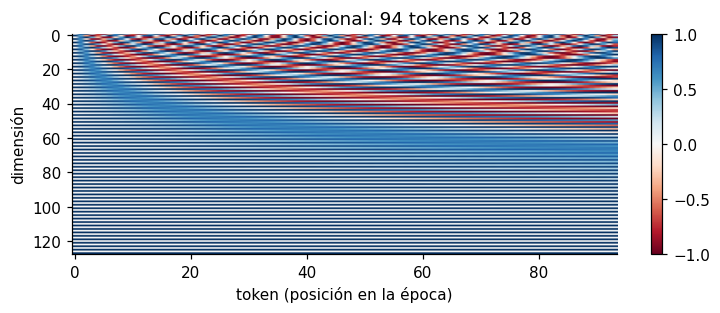

In [7]:
# Función para la codificación posicional
def positional_encoding(n_tokens, d_model):
    pos = torch.arange(n_tokens).unsqueeze(1).float()
    div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
    pe = torch.zeros(n_tokens, d_model)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe


plt.figure(figsize=(8, 2.6))
plt.imshow(positional_encoding(94, 128).T, aspect="auto", cmap="RdBu")
plt.xlabel("token (posición en la época)")
plt.ylabel("dimensión")
plt.title("Codificación posicional: 94 tokens × 128")
plt.colorbar()
plt.show()

### 3.3 Capa de Transformer

La **atención** (4 cabezas de 32 dimensiones) permite que cada token combine información de los otros 93, de modo que la representación de un momento de la época tenga en cuenta lo que ocurre en el resto. Después, una red de dos capas procesa cada token (128 → 256 → 128).

Ambas partes llevan conexión residual y LayerNorm antes de cada una (*pre-norm*), lo que estabiliza el entrenamiento. La salida mantiene el tamaño de la entrada: 94 × 128.

In [8]:
# Una capa de Transformer
class PreNormLayer(nn.Module):
    def __init__(self, d_model, nhead, d_ff, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout),
                                nn.Linear(d_ff, d_model), nn.Dropout(dropout))

    def forward(self, x, need_weights=False):
        h = self.norm1(x)
        a, w = self.attn(h, h, h, need_weights=need_weights, average_attn_weights=True)
        x = x + a                         # residual de la atención
        x = x + self.ff(self.norm2(x))    # residual de la red pequeña
        return x, w


tokens = h.transpose(1, 2) + positional_encoding(94, 128)   # (1, 94, 128)
capa = PreNormLayer(128, 4, 256, 0.1)
salida, pesos = capa(tokens, need_weights=True)
print("tokens:", tuple(tokens.shape), "→ salida:", tuple(salida.shape), "| pesos de atención:", tuple(pesos.shape))

tokens: (1, 94, 128) → salida: (1, 94, 128) | pesos de atención: (1, 94, 94)


### 3.4 SleepEffFormer

Con las piezas anteriores se arma un clasificador de una época basado en SleepEffFormer (Paul et al., 2026), reimplementado para este trabajo:

CNN → codificación posicional → 2 capas de Transformer → LayerNorm → promedio de los 94 tokens → capa lineal 128 → 5.

Las capas lineales se inicializan con Xavier y las convoluciones con Kaiming.

In [9]:
# Clasificador de una época
class SleepEffFormer(nn.Module):
    def __init__(self, n_classes=5, d_model=128, nhead=4, n_layers=2, d_ff=256,
                 cnn_dropout=0.25, tf_dropout=0.1, head_dropout=0.25):
        super().__init__()
        blocks = []
        for i in range(len(CNN_KERNELS)):
            blocks += [nn.Conv1d(CNN_CHANNELS[i], CNN_CHANNELS[i + 1], CNN_KERNELS[i], CNN_STRIDES[i],
                                 CNN_PADDINGS[i], bias=False),
                       nn.BatchNorm1d(CNN_CHANNELS[i + 1]), nn.GELU(), nn.Dropout(cnn_dropout)]
        self.cnn = nn.Sequential(*blocks)
        with torch.no_grad():
            self.n_tokens = self.cnn(torch.zeros(1, 1, 3000)).shape[-1]  # 94
        self.register_buffer("pe", positional_encoding(self.n_tokens, d_model).unsqueeze(0))
        self.pos_dropout = nn.Dropout(tf_dropout)
        self.layers = nn.ModuleList([PreNormLayer(d_model, nhead, d_ff, tf_dropout) for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(d_model, n_classes))
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        h = self.cnn(x).transpose(1, 2)        # (B, 94, 128)
        h = self.pos_dropout(h + self.pe)
        for layer in self.layers:
            h, _ = layer(h)
        return self.head(self.norm(h).mean(1))  # promedio de los 94 tokens -> 5 logits


sef = SleepEffFormer().eval()
print("parámetros:", f"{sum(p.numel() for p in sef.parameters()):,}", "| logits:", tuple(sef(x).shape))

parámetros: 367,141 | logits: (1, 5)


### 3.5 Codificador de época

De SleepEffFormer se toma todo menos la cabeza de clasificación: cada época queda resumida en un vector de 128.

En la CNN se reemplaza BatchNorm por **GroupNorm**. El mismo codificador procesa Fpz-Cz, Pz-Oz y EOG, que tienen estadísticas distintas, y cada lote mezcla canales en proporciones diferentes; con BatchNorm, las estadísticas acumuladas no corresponden a ninguna combinación real y el modelo rendía mucho peor en predicción. GroupNorm normaliza cada época por separado.

In [10]:
# Codificador de época: CNN + Transformer, sin la cabeza
class EpochEncoder(nn.Module):
    """CNN + Transformer de SleepEffFormer, sin la cabeza: (N, 3000) -> (N, 128)."""

    def __init__(self):
        super().__init__()
        base = SleepEffFormer()
        for i, mod in enumerate(base.cnn):
            if isinstance(mod, nn.BatchNorm1d):
                base.cnn[i] = nn.GroupNorm(8, mod.num_features)
        self.cnn, self.pos_dropout, self.layers, self.norm = base.cnn, base.pos_dropout, base.layers, base.norm
        self.register_buffer("pe", base.pe)

    def forward(self, x):
        h = self.cnn(x.unsqueeze(1)).transpose(1, 2)
        h = self.pos_dropout(h + self.pe)
        for layer in self.layers:
            h, _ = layer(h)
        return self.norm(h).mean(1)


codificador = EpochEncoder().eval()
print("una época (1, 3000) →", tuple(codificador(x[:, 0]).shape))

una época (1, 3000) → (1, 128)


### 3.6 Modelo completo

La red recibe trozos de **20 épocas seguidas** de una misma noche:

- `sig`: (B, 20, 3, 3000), con Fpz-Cz, Pz-Oz y EOG;
- `emg`: (B, 20, 30), la envolvente del EMG;
- `mask`: (B, 4), los canales presentes: [fpz, pz, eog, emg].

Y los procesa así:

1. **Codificador de época**, compartido por los tres canales de 100 Hz, más un vector aprendido que identifica cada canal.
2. **EMG:** una red pequeña 30 → 64 → 128.
3. **Fusión:** promedio de los canales presentes junto con la máscara, para que la red sepa qué combinación recibe (capa lineal 132 → 128).
4. **BiLSTM** de una capa (128 por sentido) sobre las 20 épocas: un sentido recorre las épocas anteriores y el otro las siguientes.
5. **Capa lineal 256 → 5** para cada época.

In [11]:
# El modelo completo
class CnnBiLSTM(nn.Module):
    def __init__(self, d=128, hidden=128, n_classes=5, dropout=0.3):
        super().__init__()
        self.d = d
        self.encoder = EpochEncoder()
        self.channel_emb = nn.Parameter(torch.zeros(3, d))          # un vector por canal (fpz, pz, eog)
        self.emg = nn.Sequential(nn.Linear(30, 64), nn.GELU(), nn.Linear(64, d))
        self.fuse = nn.Linear(d + 4, d)
        self.lstm = nn.LSTM(d, hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(2 * hidden, n_classes)

    def forward(self, sig, emg, mask):
        b, length = sig.shape[:2]
        feats = sig.new_zeros(b, length, 4, self.d, dtype=torch.float32)
        for c in range(3):  # solo se codifican los canales presentes
            sel = mask[:, c]
            if sel.any():
                x = sig[sel][:, :, c].reshape(-1, sig.shape[-1])
                feats[sel, :, c] = (self.encoder(x).float() + self.channel_emb[c]).reshape(int(sel.sum()), length, self.d)
        sel = mask[:, 3]
        if sel.any():
            feats[sel, :, 3] = self.emg(emg[sel]).float()
        m = mask.float()[:, None, :, None]
        pooled = (feats * m).sum(2) / m.sum(2).clamp(min=1.0)              # promedio de los presentes
        h = self.fuse(torch.cat([pooled, mask.float()[:, None, :].expand(b, length, 4)], -1))
        h, _ = self.lstm(self.dropout(F.gelu(h)))
        return self.out(self.dropout(h))


modelo = CnnBiLSTM().eval()
L = 20
sig = torch.from_numpy(np.stack([ejemplo[k][e:e + L] for k in ("fpz", "pz", "eog")], 1).astype(np.float32))[None]
emg = torch.from_numpy(ejemplo["emg"][e:e + L])[None]
mask = torch.tensor([mascara("fpz_eog")])
print("sig", tuple(sig.shape), "· emg", tuple(emg.shape), "· máscara", mask.tolist(), "→", tuple(modelo(sig, emg, mask).shape))
print("parámetros:", f"{sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

sig (1, 20, 3, 3000) · emg (1, 20, 30) · máscara [[True, False, True, False]] → (1, 20, 5)
parámetros: 659,685


## 4. Datos de entrenamiento

- **Trozos de 20 épocas:** en cada pasada, cada noche se divide en trozos de 20 épocas seguidas, con un desfase al azar entre 0 y 19, de modo que una época no quede siempre en el borde. Los trozos se barajan y se agrupan de a 8.
- **Canales al azar:** a cada trozo se le asigna una de las 12 combinaciones. Fpz-Cz solo y Pz-Oz solo tienen el doble de probabilidad, por ser los casos más difíciles.
- **Pesos por clase:** balanceado^0.44, como en el XGBoost.

In [12]:
# Hiperparámetros, noches en memoria y trozos de entrenamiento
HP = dict(seq_len=20, batch=8, lr=3e-4, weight_decay=1e-4, max_epochs=100, min_epochs=40, patience=15, clip=1.0,
          ema=0.999, alpha=0.44, stride=10)
SAMPLE_WEIGHT = {c: (2.0 if c in ("fpz", "pz") else 1.0) for c in CONFIGS}
VAL_CONFIGS = ("fpz", "pz", "eeg2_eog_emg")


class Nights:
    """Noches concatenadas en tensores del dispositivo, con el inicio y el largo de cada una."""

    def __init__(self, data, nights, device):
        self.nights = list(nights)
        lengths = [len(data[n]["y"]) for n in self.nights]
        self.start = np.concatenate([[0], np.cumsum(lengths)[:-1]]).astype(np.int64)
        self.length = np.array(lengths)
        self.sig = torch.from_numpy(np.concatenate(
            [np.stack([data[n][k] for k in ("fpz", "pz", "eog")], 1) for n in self.nights])).to(device)
        self.emg = torch.from_numpy(np.concatenate([data[n]["emg"] for n in self.nights])).to(device)
        self.y = torch.from_numpy(np.concatenate([data[n]["y"] for n in self.nights])).to(device)


def class_weights(y, alpha):
    counts = np.bincount(y, minlength=5).astype(float)
    return (len(y) / (5 * np.maximum(counts, 1))) ** alpha


def train_windows(nd, rng, L):
    """Inicios de los trozos de una pasada: un desfase al azar por noche, trozos sin traslape, barajados."""
    starts = []
    for s, n in zip(nd.start, nd.length):
        off = int(rng.integers(0, L)) if n > L else 0
        starts += [s + o for o in range(off, max(n - L, 0) + 1, L)]
    return rng.permutation(np.array(starts, dtype=np.int64))


p_cfg = np.array([SAMPLE_WEIGHT[c] for c in CONFIGS])
print("probabilidad de cada combinación:", {c: round(float(p), 3) for c, p in zip(CONFIGS, p_cfg / p_cfg.sum())})

probabilidad de cada combinación: {'fpz': 0.143, 'pz': 0.143, 'eeg2': 0.071, 'fpz_eog': 0.071, 'pz_eog': 0.071, 'eeg2_eog': 0.071, 'fpz_emg': 0.071, 'pz_emg': 0.071, 'eeg2_emg': 0.071, 'fpz_eog_emg': 0.071, 'pz_eog_emg': 0.071, 'eeg2_eog_emg': 0.071}


## 5. Predicción y métricas

Para predecir una noche, se recorre con ventanas de 20 épocas que avanzan de 10 en 10. Así, cada época aparece en dos ventanas, una vez cerca del borde y otra en el centro, y se promedian las dos probabilidades.

Se usan las mismas métricas del XGBoost: **MF1** (la principal), **κ de Cohen** y **F1 de N1**.

In [13]:
# Función para calcular las métricas
def compute_metrics(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(5), average=None, zero_division=0)
    return {"acc": accuracy_score(y_true, y_pred), "mf1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"f1_{s}": v for s, v in zip(ESTADIOS, f1)},
            "confusion": confusion_matrix(y_true, y_pred, labels=range(5))}

In [14]:
# Funciones para predecir una noche con una combinación de canales y evaluar
def _amp(device):
    return torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda")


@torch.no_grad()
def predict_night(model, nd, i, cfg, device, L=None, stride=None, batch=64):
    """Probabilidades (n, 5) de la noche i con la combinación cfg (ver arriba)."""
    model.eval()
    L, stride = L or HP["seq_len"], stride or HP["stride"]
    s, n = int(nd.start[i]), int(nd.length[i])
    L = min(L, n)
    starts = list(range(0, n - L + 1, stride))
    if starts[-1] != n - L:
        starts.append(n - L)
    acc = torch.zeros(n, 5, device=device)
    cnt = torch.zeros(n, 1, device=device)
    mask1 = torch.tensor(mascara(cfg), device=device)
    for j in range(0, len(starts), batch):
        st = torch.tensor(starts[j:j + batch], device=device)
        idx = s + st[:, None] + torch.arange(L, device=device)
        with _amp(device):
            logits = model(nd.sig[idx].float() if device.type != "cuda" else nd.sig[idx], nd.emg[idx],
                           mask1.expand(len(st), 4))
        p = torch.softmax(logits.float(), -1)
        loc = st[:, None] + torch.arange(L, device=device)
        acc.index_add_(0, loc.reshape(-1), p.reshape(-1, 5))
        cnt.index_add_(0, loc.reshape(-1), torch.ones(loc.numel(), 1, device=device))
    return (acc / cnt).cpu().numpy()


def evaluate(model, nd, configs, device):
    y = nd.y.cpu().numpy()
    out = {}
    for cfg in configs:
        p = np.concatenate([predict_night(model, nd, i, cfg, device) for i in range(len(nd.nights))])
        out[cfg] = compute_metrics(y, p.argmax(1))
    return out

## 6. Entrenamiento

- **Pérdida:** entropía cruzada con pesos por clase.
- **Optimizador:** AdamW (tasa 3·10⁻⁴, *weight decay* 10⁻⁴), con decaimiento coseno hasta 10⁻⁶ en 100 pasadas, recorte del gradiente a norma 1.0 y precisión mixta en GPU.
- **EMA:** promedio exponencial de los pesos (0.999), más estable que los pesos del último paso; es el que se evalúa y se guarda.
- **Validación:** en cada pasada, con Fpz-Cz solo, Pz-Oz solo y los 4 canales; el puntaje es el promedio de sus MF1.
- **Parada temprana:** máximo 100 pasadas; se detiene si pasan 15 sin mejorar, nunca antes de la 40, y se conservan los pesos de la mejor.

In [15]:
# Promedio exponencial de los pesos (EMA)
class EMA:
    """Promedio exponencial de los pesos del modelo."""

    def __init__(self, model, decay):
        self.decay, self.steps = decay, 0
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.steps += 1
        w = 1 - min(self.decay, (1 + self.steps) / (10 + self.steps))   # al inicio sigue al modelo más de cerca
        for e, m in zip(self.model.parameters(), model.parameters()):
            e.lerp_(m.detach(), w)
        for e, m in zip(self.model.buffers(), model.buffers()):
            if e.dtype.is_floating_point:
                e.lerp_(m, w)
            else:
                e.copy_(m)

In [16]:
# Función de entrenamiento
def fit(train, val_nd, log_path, device, seed=SEED, max_epochs=None):
    """Entrena y devuelve (mejor pasada, pesos EMA de la mejor pasada)."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    max_epochs = max_epochs or HP["max_epochs"]
    L, bs = HP["seq_len"], HP["batch"]

    model = CnnBiLSTM().to(device)
    ema = EMA(model, HP["ema"])
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=HP["max_epochs"], eta_min=1e-6)
    w = torch.tensor(class_weights(train.y.cpu().numpy(), HP["alpha"]), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=w)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    cfg_names = list(CONFIGS)
    p = np.array([SAMPLE_WEIGHT[c] for c in cfg_names])
    p = p / p.sum()
    masks = torch.tensor([mascara(c) for c in cfg_names], device=device)

    best, best_state = {"score": -1.0, "epoch": 0}, None
    with open(log_path, "w", newline="") as f:
        wr = csv.writer(f)
        wr.writerow(["epoch", "train_loss", *[f"val_mf1_{c}" for c in VAL_CONFIGS], "val_f1_N1_fpz", "score", "lr"])
        for epoch in range(1, max_epochs + 1):
            model.train()
            starts = train_windows(train, rng, L)
            total, nb = 0.0, 0
            for j in range(0, len(starts), bs):
                st = torch.from_numpy(starts[j:j + bs]).to(device)
                idx = st[:, None] + torch.arange(L, device=device)
                mk = masks[torch.from_numpy(rng.choice(len(cfg_names), size=len(st), p=p)).to(device)]
                sig = train.sig[idx] if device.type == "cuda" else train.sig[idx].float()
                with _amp(device):
                    logits = model(sig, train.emg[idx], mk)
                    loss = criterion(logits.float().reshape(-1, 5), train.y[idx].reshape(-1))
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), HP["clip"])
                scaler.step(opt)
                scaler.update()
                ema.update(model)
                total += loss.item()
                nb += 1
            lr = opt.param_groups[0]["lr"]
            sched.step()

            val = evaluate(ema.model, val_nd, VAL_CONFIGS, device)
            score = float(np.mean([val[c]["mf1"] for c in VAL_CONFIGS]))
            wr.writerow([epoch, total / nb, *[val[c]["mf1"] for c in VAL_CONFIGS], val["fpz"]["f1_N1"], score, lr])
            f.flush()
            if score > best["score"]:
                best = {"score": score, "epoch": epoch}
                best_state = copy.deepcopy(ema.model.state_dict())
            if epoch >= HP["min_epochs"] and epoch - best["epoch"] >= HP["patience"]:
                break
    return best, best_state

## 7. Validación cruzada y modelo final

Se hacen 6 entrenamientos: uno por cada fold de `particiones.json`, cuyas predicciones fuera de fold cubren a los 62 sujetos de desarrollo, y el modelo final, que se entrena con los sujetos de desarrollo y predice los 16 de test.

Cada entrenamiento predice sus noches con las 12 combinaciones de canales. El modelo final se guarda en `modelo/cnn_bilstm/modelo_final.pt`, con sus pesos y los hiperparámetros para reconstruir la red.

In [17]:
# Funciones para correr un entrenamiento completo
NOMBRES = ["fold_0"] if PRUEBA else ["final", "fold_0", "fold_1", "fold_2", "fold_3", "fold_4"]


def fold_spec(name):
    return particion["final"] if name == "final" else particion["folds"][int(name.split("_")[1])]


def listo(name):
    if name == "final" and not CKPT_PATH.exists():   # el final también necesita su modelo guardado
        return False
    return (PREDICCIONES / f"{name}.npz").exists()


def run_fold(name):
    fold = fold_spec(name)
    device = torch.device(DISPOSITIVO)
    available = sorted(p.stem for p in NOCHES.glob("SC4*.npz"))
    of = lambda subjects: [n for n in available if int(n[3:5]) in set(subjects)]  # noqa: E731
    tr, va, te = of(fold["train"]), of(fold["val"]), of(fold["test"])
    if PRUEBA:
        tr, va, te = tr[:6], va[:2], te[:2]
    data = {n: dict(np.load(NOCHES / f"{n}.npz")) for n in tr + va}
    train_nd, val_nd = Nights(data, tr, device), Nights(data, va, device)
    best, best_state = fit(train_nd, val_nd, LOGS / f"{name}_log.csv", device, max_epochs=2 if PRUEBA else None)
    del train_nd, val_nd, data

    model = CnnBiLSTM().to(device)
    model.load_state_dict(best_state)
    if name == "final":
        checkpoint = {
            # Pesos de la red (los EMA de la mejor pasada)
            "model_state_dict": {k: v.cpu() for k, v in best_state.items()},

            # Hiperparámetros de arquitectura (necesarios para reconstruir la red)
            "ARQUITECTURA": dict(d=128, hidden=128, n_classes=5, dropout=0.3),

            # Para predecir igual que aquí (ventanas de 20 con paso 10) y armar la máscara de canales
            "HP": HP,
            "CONFIGS": CONFIGS,
            "MODALIDADES": MODALIDADES,
            "ESTADIOS": ESTADIOS,

            # Referencia del entrenamiento
            "mejor_pasada": best["epoch"],
            "puntaje_val": best["score"],
        }
        MODELO.mkdir(parents=True, exist_ok=True)
        torch.save(checkpoint, CKPT_PATH)
    test_data = {n: dict(np.load(NOCHES / f"{n}.npz")) for n in te}
    test_nd = Nights(test_data, te, device)
    arr = {}
    for cfg in CONFIGS:
        for i, n in enumerate(te):
            arr[f"{cfg}__{n}"] = predict_night(model, test_nd, i, cfg, device).astype(np.float32)
    for n in te:
        arr[f"y__{n}"], arr[f"pos__{n}"] = test_data[n]["y"], test_data[n]["pos"]
    np.savez_compressed(PREDICCIONES / f"{name}.npz", **arr)
    (LOGS / f"{name}_resumen.json").write_text(json.dumps(
        {"mejor_pasada": best["epoch"], "puntaje_val": best["score"]}))

Los 6 entrenamientos corren en paralelo en la misma GPU, cada uno en un proceso aparte. Como cada uno fija su semilla, el resultado es el mismo que entrenándolos uno tras otro. La tabla muestra el MF1 de validación de cada uno con Fpz-Cz, Pz-Oz y los 4 canales, y el mejor puntaje alcanzado.

In [18]:
# Funciones para seguir los entrenamientos que corren en paralelo
def _en_proceso_aparte(name):
    log = open(LOGS / f"{name}.out", "a")
    sys.stdout = sys.stderr = log
    # El proceso principal ya hizo cálculos en CPU (sección 3) y OpenMP no es seguro después de fork:
    # la copia usa un solo hilo de CPU. El trabajo pesado va en la GPU.
    torch.set_num_threads(1)
    run_fold(name)


def avance(name):
    try:
        lg = pd.read_csv(LOGS / f"{name}_log.csv")
    except (FileNotFoundError, pd.errors.EmptyDataError):
        return {}
    if lg.empty:
        return {}
    u = lg.iloc[-1]
    return {"pasada": int(u.epoch), "val fpz": round(float(u.val_mf1_fpz), 3), "val pz": round(float(u.val_mf1_pz), 3),
            "val 4ch": round(float(u.val_mf1_eeg2_eog_emg), 3), "mejor": round(float(lg.score.max()), 3),
            "mejor pasada": int(lg.score.idxmax()) + 1}


def vivo(pid):
    try:
        os.kill(pid, 0)
        return True
    except OSError:
        return False

In [19]:
# Lanzar los 6 entrenamientos y mostrar su avance
if EN_PARALELO == 1:
    for name in NOMBRES:
        if not listo(name):
            run_fold(name)
            print(name, "listo", avance(name))
else:
    ctx = mp.get_context("fork")
    corriendo, fallidos = {}, set()
    for name in NOMBRES:  # entrenamientos que siguen vivos de una ejecución anterior de esta celda
        pid_file = LOGS / f"{name}.pid"
        if pid_file.exists() and not listo(name) and vivo(int(pid_file.read_text())):
            corriendo[name] = int(pid_file.read_text())
    while True:
        mp.active_children()  # recoge los procesos que ya terminaron
        for name, pid in list(corriendo.items()):
            if listo(name) or not vivo(pid):
                corriendo.pop(name)
                if not listo(name):
                    fallidos.add(name)
        pendientes = [n for n in NOMBRES if not listo(n) and n not in corriendo and n not in fallidos]
        while pendientes and len(corriendo) < EN_PARALELO:
            name = pendientes.pop(0)
            proc = ctx.Process(target=_en_proceso_aparte, args=(name,))
            proc.start()
            (LOGS / f"{name}.pid").write_text(str(proc.pid))
            corriendo[name] = proc.pid
        estado = lambda n: "listo" if listo(n) else "corriendo" if n in corriendo else "ERROR" if n in fallidos else "en cola"  # noqa: E731
        clear_output(wait=True)
        print(f"listos {sum(listo(n) for n in NOMBRES)}/{len(NOMBRES)}")
        display(pd.DataFrame([{"entrenamiento": n, "estado": estado(n), **avance(n)} for n in NOMBRES]).fillna(""))
        for name in sorted(fallidos):
            print(f"\nERROR en {name}:\n" + "".join(open(LOGS / f"{name}.out").readlines()[-15:]))
        if not corriendo and not [n for n in NOMBRES if not listo(n) and n not in fallidos]:
            break
        time.sleep(10 if PRUEBA else 60)
print("Terminado.")

listos 6/6


,entrenamiento,estado,pasada,val fpz,val pz,val 4ch,mejor,mejor pasada
0,final,listo,100,0.745,0.732,0.775,0.752,94
1,fold_0,listo,78,0.740,0.707,0.755,0.735,63
2,fold_1,listo,74,0.764,0.702,0.788,0.753,59
3,fold_2,listo,74,0.735,0.642,0.754,0.715,59
4,fold_3,listo,100,0.791,0.750,0.833,0.792,90
5,fold_4,listo,59,0.799,0.743,0.809,0.790,44


Terminado.


## 8. Resultados

### Entrenamiento

Puntaje de validación en cada pasada. La línea punteada marca la pasada 40, el mínimo antes de permitir la parada.

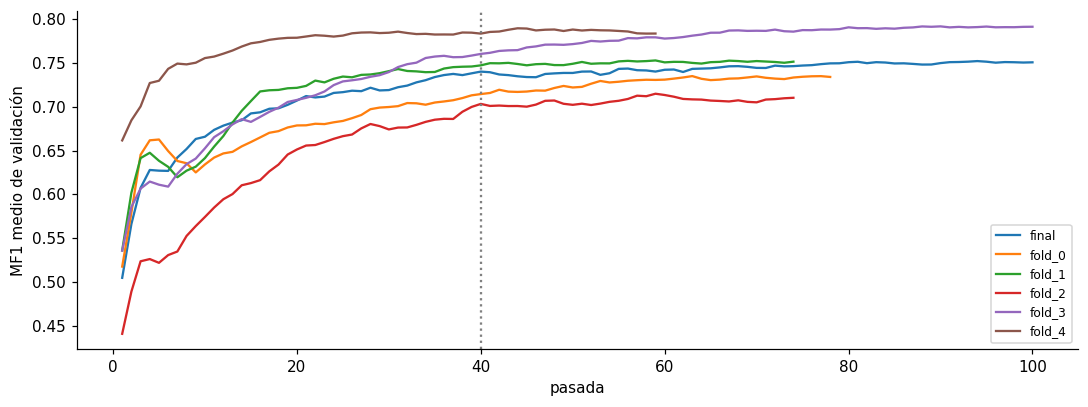

,pasadas,mejor pasada,puntaje de validación
entrenamiento,,,
final,100,94,0.752
fold_0,78,63,0.735
fold_1,74,59,0.753
fold_2,74,59,0.715
fold_3,100,90,0.792
fold_4,59,44,0.790


In [21]:
# Curvas de entrenamiento y mejor pasada de cada entrenamiento
fig, ax = plt.subplots(figsize=(10, 3.8))
filas = []
for name in NOMBRES:
    lg = pd.read_csv(LOGS / f"{name}_log.csv")
    r = json.loads((LOGS / f"{name}_resumen.json").read_text())
    ax.plot(lg.epoch, lg.score, label=name)
    filas.append({"entrenamiento": name, "pasadas": len(lg), "mejor pasada": r["mejor_pasada"],
                  "puntaje de validación": round(r["puntaje_val"], 3)})
ax.axvline(HP["min_epochs"], ls=":", color="gray")
ax.set_xlabel("pasada")
ax.set_ylabel("MF1 medio de validación")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(filas).set_index("entrenamiento")

### Por combinación

**CV:** predicciones fuera de fold de los 62 sujetos de desarrollo. **Test:** los 16 sujetos de test, predichos con el modelo final.

In [22]:
# Función para leer las predicciones de un entrenamiento
def load_fold_preds(name):
    """combinación -> noche -> (y, probabilidades)"""
    z = np.load(PREDICCIONES / f"{name}.npz")
    out = {}
    for k in z.files:
        if k.startswith(("y__", "pos__")):
            continue
        cfg, n = k.split("__")
        out.setdefault(cfg, {})[n] = (z[f"y__{n}"], z[k])
    return out


def metrics_of(preds):
    y = np.concatenate([y for y, _ in preds.values()])
    p = np.concatenate([p.argmax(1) for _, p in preds.values()])
    return compute_metrics(y, p)


oof = {c: {} for c in CONFIGS}
for name in [n for n in NOMBRES if n != "final"]:
    for c, d in load_fold_preds(name).items():
        oof[c].update(d)
test = load_fold_preds("final") if "final" in NOMBRES else None

In [23]:
# Métricas de CV y de test por combinación
filas = []
for c in CONFIGS:
    cv = metrics_of(oof[c])
    fila = {"combinación": c, "CV MF1": cv["mf1"], "CV κ": cv["kappa"], "CV F1 N1": cv["f1_N1"]}
    if test:
        te = metrics_of(test[c])
        fila.update({"test MF1": te["mf1"], "test κ": te["kappa"], "test F1 N1": te["f1_N1"]})
    filas.append(fila)
pd.DataFrame(filas).set_index("combinación").style.format(precision=3)

,CV MF1,CV κ,CV F1 N1,test MF1,test κ,test F1 N1
combinación,,,,,,
fpz,0.754,0.741,0.531,0.750,0.727,0.496
pz,0.721,0.707,0.499,0.698,0.659,0.452
eeg2,0.767,0.759,0.557,0.755,0.733,0.502
fpz_eog,0.780,0.767,0.558,0.761,0.733,0.522
pz_eog,0.769,0.758,0.552,0.727,0.687,0.491
eeg2_eog,0.783,0.775,0.572,0.765,0.740,0.516
fpz_emg,0.756,0.744,0.533,0.751,0.725,0.501
pz_emg,0.725,0.712,0.504,0.707,0.668,0.470
eeg2_emg,0.770,0.761,0.563,0.754,0.731,0.502


### F1 por estadio

F1 de cada estadio en el test, solo con Fpz-Cz y con los 4 canales.

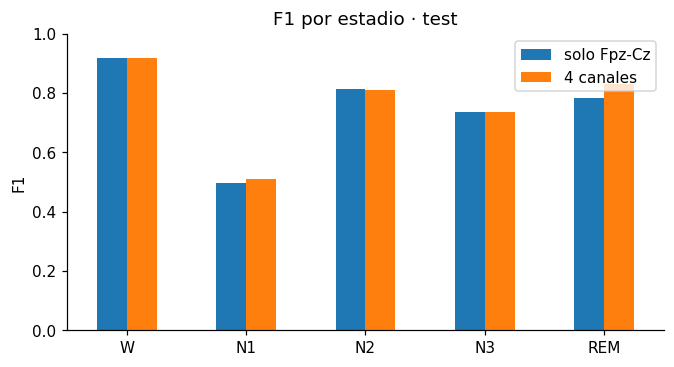

In [24]:
# F1 por estadio en el test
if test:
    f1 = pd.DataFrame({nombre: [metrics_of(test[c])[f"f1_{s}"] for s in ESTADIOS]
                       for c, nombre in [("fpz", "solo Fpz-Cz"), ("eeg2_eog_emg", "4 canales")]}, index=ESTADIOS)
    ax = f1.plot.bar(figsize=(7, 3.5), rot=0)
    ax.set_ylabel("F1")
    ax.set_ylim(0, 1)
    ax.set_title("F1 por estadio · test")
    plt.show()

## 9. Matrices de confusión

CV y test, solo con Fpz-Cz y con los 4 canales. Cada fila es el estadio real y suma 100 %.

In [25]:
# Función para graficar una matriz de confusión
def plot_confusion(cm, title, ax):
    cm = np.asarray(cm)
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n{cm[i, j]:,}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.6 else "black")
    ax.set_xticks(range(5), ESTADIOS)
    ax.set_yticks(range(5), ESTADIOS)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
    ax.set_title(title, fontsize=10)

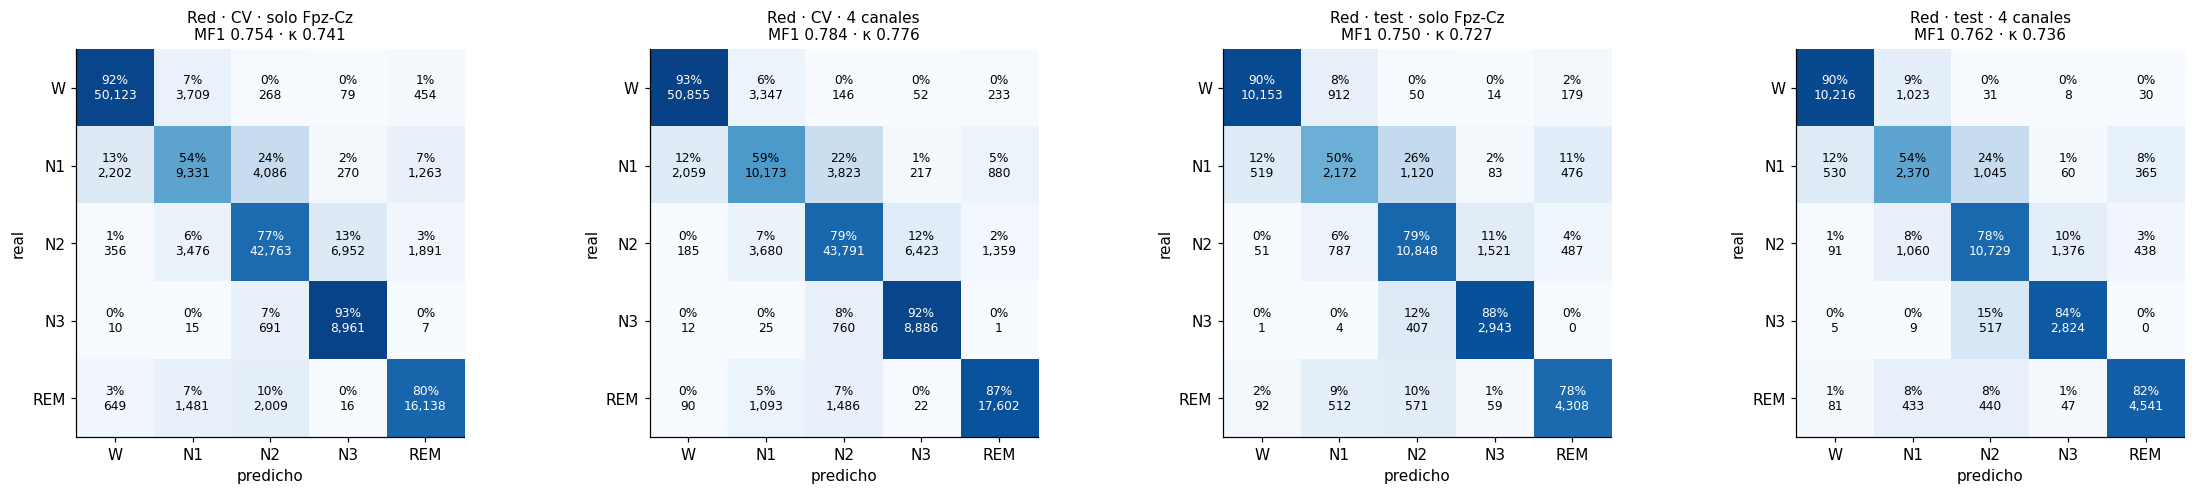

In [26]:
# Matrices de confusión de la CV y del test
fig, axes = plt.subplots(1, 4 if test else 2, figsize=(21 if test else 11, 4.6))
paneles = [(oof, "CV"), (test, "test")] if test else [(oof, "CV")]
k = 0
for preds, nombre_split in paneles:
    for c, nombre in [("fpz", "solo Fpz-Cz"), ("eeg2_eog_emg", "4 canales")]:
        m = metrics_of(preds[c])
        plot_confusion(m["confusion"], f"Red · {nombre_split} · {nombre}\nMF1 {m['mf1']:.3f} · κ {m['kappa']:.3f}", axes[k])
        k += 1
plt.tight_layout()
plt.show()

## 10. Uso del modelo guardado

Se reconstruye la red con los hiperparámetros de `modelo_final.pt`, se cargan sus pesos y se predice una noche de test solo con Fpz-Cz. La predicción coincide con la del entrenamiento.

In [27]:
# Cargar el modelo guardado y predecir una noche de test con Fpz-Cz
device = torch.device(DISPOSITIVO)
ck = torch.load(CKPT_PATH, map_location=device, weights_only=False)
modelo_final = CnnBiLSTM(**ck["ARQUITECTURA"]).to(device)
modelo_final.load_state_dict(ck["model_state_dict"])
modelo_final.eval()
print(f"modelo cargado: mejor pasada {ck['mejor_pasada']}, puntaje de validación {ck['puntaje_val']:.3f}")

n = sorted(test["fpz"])[0]
nd = Nights({n: dict(np.load(NOCHES / f"{n}.npz"))}, [n], device)
p = predict_night(modelo_final, nd, 0, "fpz", device)
print(f"{n} · solo Fpz-Cz · diferencia máxima con lo guardado: {np.abs(p - test['fpz'][n][1]).max():.1e}")

modelo cargado: mejor pasada 94, puntaje de validación 0.752
SC4001 · solo Fpz-Cz · diferencia máxima con lo guardado: 6.0e-08


In [28]:
# Las primeras épocas de esa noche: estadio real, predicho y confianza de la red
y = test["fpz"][n][0]
pd.DataFrame({"real": [ESTADIOS[v] for v in y[:10]], "predicho": [ESTADIOS[v] for v in p[:10].argmax(1)],
              "confianza": p[:10].max(1).round(2)})

,real,predicho,confianza
0,W,W,1.0
1,W,W,1.0
2,W,W,1.0
3,W,W,1.0
4,W,W,1.0
5,W,W,1.0
6,W,W,1.0
7,W,W,1.0
8,W,W,1.0
9,W,W,1.0


## 11. Conclusiones

- Una sola red sirve para las 12 combinaciones: al sortear los canales en cada trozo de entrenamiento, aprende a clasificar con lo que tenga.
- Frente al XGBoost, la red queda un poco por debajo en MF1 en la CV, pero **le gana en N1**, la clase más difícil.
- Las dos se equivocan de formas distintas: el XGBoost mira rasgos de cada época y la red aprende de la señal cruda y de las 20 épocas vecinas.